In [3]:
install.packages("BiocManager", force=TRUE)
library("BiocManager")
BiocManager::install("pwalign", force=TRUE)
BiocManager::install("ape", force=TRUE)
BiocManager::install("ORFik", force=TRUE)
BiocManager::install("Biostrings", force=TRUE)

# Load required packages
library(Biostrings)  # For sequence manipulation
library(ORFik)       # For finding ORFs
library(ape)         # For reading GenBank files
library(pwalign)     # For sequence alignments

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cloud.r-project.org

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'pwalign'

Installation paths not writeable, unable to update packages
  path: /usr/lib/R/library
  packages:
    cluster, codetools, foreign, nlme, spatial, survival

Old packages: 'Biostrings', 'bit64', 'colorspace', 'curl', 'Deriv', 'diffobj',
  'edgeR', 'future', 'future.apply', 'gargle', 'gert', 'ggstats', 'globals',
  'googledrive', 'googlesheets4', 'httr', 'igraph', 'knitr', 'lambda.r',
  'lava', 'listenv', 'litedown', 'lme4', 'markdown', 'modeltools', 'poorman',
  'priorsense', 'pROC', 'progressr', 'projpred', 'RcppArmadillo', 'readxl',
  'rmarkdown', 'roxygen2', 's2', 'S4Arrays', 'S4Vectors', 'selectr', 'sf',
  

In [4]:
# Hint: set working directory with setwd()

# PART 1: Analyzing sequence composition and open reading frames ----------


# Retrieve SARS-CoV-2 genome sequence from GenBank
sars_cov2_genome <- read.GenBank("NC_045512", as.character = T)

# Convert the sequence uppercase character vector
sars_cov2_sequence <- toupper(paste(sars_cov2_genome[[1]], collapse = ""))

# Display the sequence
sars_cov2_sequence

[1] "ATTAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGCTGTCACTCGGCTGCATGCTTAGTGCACTCACGCAGTATAATTAATAACTAATTACTGTCGTTGACAGGACACGAGTAACTCGTCTATCTTCTGCAGGCTGCTTACGGTTTCGTCCGTGTTGCAGCCGATCATCAGCACATCTAGGTTTCGTCCGGGTGTGACCGAAAGGTAAGATGGAGAGCCTTGTCCCTGGTTTCAACGAGAAAACACACGTCCAACTCAGTTTGCCTGTTTTACAGGTTCGCGACGTGCTCGTACGTGGCTTTGGAGACTCCGTGGAGGAGGTCTTATCAGAGGCACGTCAACATCTTAAAGATGGCACTTGTGGCTTAGTAGAAGTTGAAAAAGGCGTTTTGCCTCAACTTGAACAGCCCTATGTGTTCATCAAACGTTCGGATGCTCGAACTGCACCTCATGGTCATGTTATGGTTGAGCTGGTAGCAGAACTCGAAGGCATTCAGTACGGTCGTAGTGGTGAGACACTTGGTGTCCTTGTCCCTCATGTGGGCGAAATACCAGTGGCTTACCGCAAGGTTCTTCTTCGTAAGAACGGTAATAAAGGAGCTGGTGGCCATAGTTACGGCGCCGATCTAAAGTCATTTGACTTAGGCGACGAGCTTGGCACTGATCCTTATGAAGATTTTCAAGAAAACTGGAACACTAAACATAGCAGTGGTGTTACCCGTGAACTCATGCGTGAGCTTAACGGAGGGGCATACACTCGCTATGTCGATAACAACTTCTGTGGCCCTGATGGCTACCCTCTTGAGTGCATTAAAGACCTTCTAGCACGTGCTGGTAAAGCTTCATGCACTTTGTCCGAACAACTGGACTTTATTGACACTAAGAGGGGTGTATACTGCTGCCGTGAACATGAGCATGAAATTGCTTGGTACACGGAACGTTCTGAAAAGAGCTATGAATTGCAGACACCTTTTGAAATTAAATTGGCAAAGAAATTTGACACCTTCAATGGGGAATGTCCAAATTTTGTATTTCCCTTAAATTCCATAATCAAGACTATTCAACCAAGGGTTGAAAAGAAAAAGCTTGATGGCTTTATGGGTAGAATTCGATCTGTCTATCCAGTTGCGTCACCAAATGAATGCAACCAAATGTGCCTTTCAACTCTCATGAAGTGTGATCATTGTGGTGAAACTTCATGGCAGACGGGCGATTTTGTTAAAGCCACTTGCGAATTTTGTGGCACTGAGAATTTGACTAAAGAAGGTGCCACTACTTGTGGTTACTTACCCCAAAATGCTGTTGTTAAAATTTATTGTCCAGCATGTCACAATTCAGAAGTAGGACCTGAGCATAGTCTTGCCGAATACCATAATGAATCTGGCTTGAAAACCATTCTTCGTAAGGGTGGTCGCACTATTGCCTTTGGAGGCTGTGTGTTCTCTTATGTTGGTTGCCATAACAAGTGTGCCTATTGGGTTCCACGTGCTAGCGCTAACATAGGTTGTAACCATACAGGTGTTGTTGGAGAAGGTTCCGAAGGTCTTAATGACAACCTTCTTGAAATACTCCAAAAAGAGAAAGTCAACATCAATATTGTTGGTGACTTTAAACTTAATGAAGAGATCGCCATTATTTTGGCATCTTTTTCTGCTTCCACAAGTGCTTTTGTGGAAACTGTGAAAGGTTTGGATTATAAAGCATTCAAACAAATTGTTGAATCCTGTGGTAATTTTAAAGTTACAAAAGGAAAAGCTAAAAAAGGTGCCTGGAATATTGGTGAACAGAAATCAATACTGAGTCCTCTTTATGCATTTGCATCAGAGGCTGCTCGTGTTGTACGATCAATTTTCTCCCGCACTCTTGAAACTGCTCAAAATTCTGTGCGTGTTTTACAGAAGGCCGCTATAACAATACTAGATGGAATTTCACAGTATTCACTGAGACTCATTGATGCTATGATGTTCACATCTGATTTGGCTACTAACAATCTAGTTGTAATGGCCTACATTACAGGTGGTGTTGTTCAGTTGACTTCGCAGTGGCTAACTAACATCTTTGGCACTGTTTATGAAAAACTCAAACCCGTCCTTGATTGGCTTGAAGAGAAGTTTAAGGAAGGTGTAGAGTTTCTTAGAGACGGTTGGGAAATTGTTAAATTTATCTCAACCTGTGCTTGTGAAATTGTCGGTGGACAAATTGTCACCTGTGCAAAGGAAATTAAGGAGAGTGTTCAGACATTCTTTAAGCTTGTAAATAAATTTTTGGCTTTGTGTGCTGACTCTATCATTATTGGTGGAGCTAAACTTAAAGCCTTGAATTTAGGTGAAACATTTGTCACGCACTCAAAGGGATTGTACAGAAAGTGTGTTAAATCCAGAGAAGAAACTGGCCTACTCATGCCTCTAAAAGCCCCAAAAGAAATTATCTTCTTAGAGGGAGAAACACTTCCCACAGAAGTGTTAACAGAGGAAGTTGTCTTGAAAACTGGTGATTTACAACCATTAGAACAACCTACTAGTGAAGCTGTTGAAGCTCCATTGGTTGGTACACCAGTTTGTATTAACGGGCTTATGTTGCTCGAAATCAAAGACACAGAAAAGTACTGTGCCCTTGCACCTAATATGATGGTAACAAACAATACCTTCACACTCAAAGGCGGTGCACCAACAAAGGTTACTTTTGGTGATGACACTGTGATAGAAGTGCAAGGTTACAAGAGTGTGAATATCACTTTTGAACTTGATGAAAGGATTGATAAAGTACTTAATGAGAAGTGCTCTGCCTATACAGTTGAACTCGGTACAGAAGTAAATGAGTTCGCCTGTGTTGTGGCAGATGCTGTCATAAAAACTTTGCAACCAGTATCTGAATTACTTACACCACTGGGCATTGATTTAGATGAGTGGAGTATGGCTACATACTACTTATTTGATGAGTCTGGTGAGTTTAAATTGGCTTCACATATGTATTGTTCTTTCTACCCTCCAGATGAGGATGAAGAAGAAGGTGATTGTGAAGAAGAAGAGTTTGAGCCATCAACTCAATATGAGTATGGTACTGAAGATGATTACCAAGGTAAACCTTTGGAATTTGGTGCCACTTCTGCTGCTCTTCAACCTGAAGAAGAGCAAGAAGAAGATTGGTTAGATGATGATAGTCAACAAACTGTTGGTCAACAAGACGGCAGTGAGGACAATCAGACAACTACTATTCAAACAATTGTTGAGGTTCAACCTCAATTAGAGATGGAACTTACACCAGTTGTTCAGACTATTGAAGTGAATAGTTTTAGTGGTTATTTAAAACTTACTGACAATGTATACATTAAAAATGCAGACATTGTGGAAGAAGCTAAAAAGGTAAAACCAACAGTGGTTGTTAATGCAGCCAATGTTTACCTTAAACATGGAGGAGGTGTTGCAGGAGCCTTAAATAAGGCTACTAACAATGCCATGCAAGTTGAATCTGATGATTACATAGCTACTAATGGACCACTTAAAGTGGGTGGTAGTTGTGTTTTAAGCGGACACAATCTTGCTAAACACTGTCTTCATGTTGTCGGCCCAAATGTTAACAAAGGTGAAGACATTCAACTTCTTAAGAGTGCTTATGAAAATTTTAATCAGCACGAAGTTCTACTTGCACCATTATTATCAGCTGGTATTTTTGGTGCTGACCCTATACATTCTTTAAGAGTTTGTGTAGATACTGTTCGCACAAATGTCTACTTAGCTGTCTTTGATAAAAATCTCTATGACAAACTTGTTTCAAGCTTTTTGGAAATGAAGAGTGAAAAGCAAGTTGAACAAAAGATCGCTGAGATTCCTAAAGAGGAAGTTAAGCCATTTATAACTGAAAGTAAACCTTCAGTTGAACAGAGAAAACAAGATGATAAGAAAATCAAAGCTTGTGTTGAAGAAGTTACAACAACTCTGG

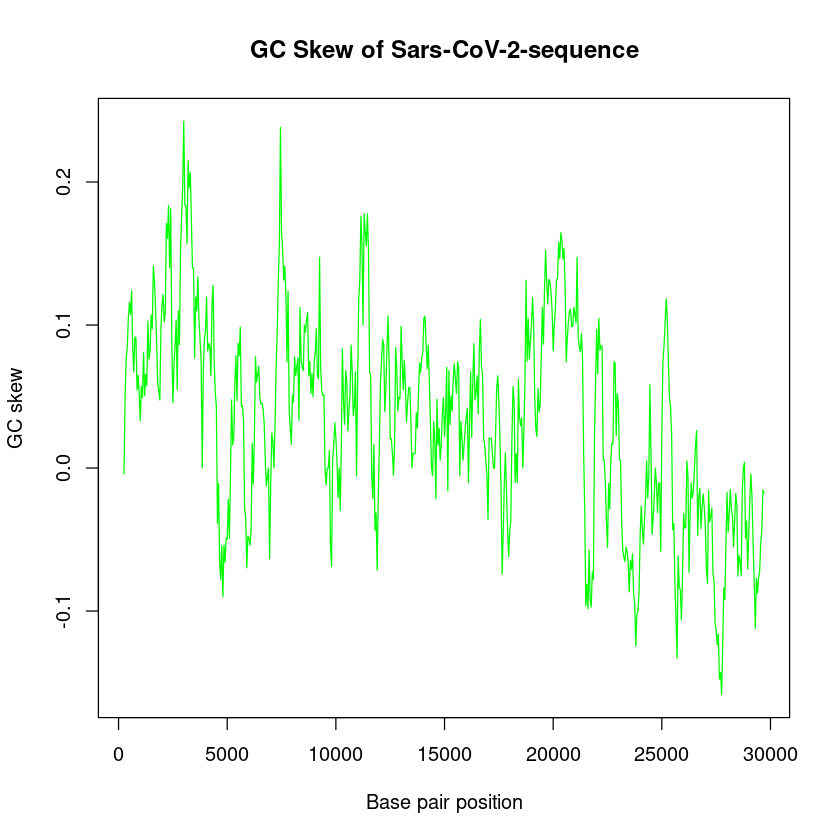

In [5]:
# 1. GC skew --------------------------------------------------------------

# Hint: DNAString(), alphabetFrequency(), for loop
# Count the limit of the DNA string
limit <- nchar(sars_cov2_sequence)
# Start position array (bp) and corresponding GC_skew values (skews, to be added later)
bp <- seq(1, limit, by = 50)
skews <- numeric(0)

for (i in bp) {
    x_start <- i
    x_end <- min(x_start + 500, limit)
        
    cur_window <- DNAString(substring(sars_cov2_sequence,x_start,x_end)) # extract subsequence
    frequencies <- alphabetFrequency(cur_window,baseOnly = TRUE) # Count the bases frequencies, showing the bases values only
    gs <- frequencies["G"]
    cs <- frequencies["C"]
    GC_skew = (gs - cs)/(gs + cs) # compute skew
    
    skews <- c(skews,GC_skew)
    
    if (x_end == limit) break
    }

# Todo: make the plot prettier and the position starts at the middle of the window, not the start.
# Make bp starts at the middle
bp <- bp + 250
# Plot GC skew against base pair position
plot(bp[1:length(skews)],skews, type="l",col = "green", main = "GC Skew of Sars-CoV-2-sequence", xlab = "Base pair position", ylab = "GC skew")

In [6]:
# 2. Identify ORFs --------------------------------------------------------

# Hint: findORFs(), which.max(), as.data.frame() for easier inspection of results
allORF <- as.data.frame(findORFs(sars_cov2_sequence, 
                                startCodon = "ATG",
                                stopCodon = c("TAA", "TAG", "TGA"),
                                longestORF = TRUE))[[1]]
allLen <- allORF$width
longest_loc <- which.max(allLen)
result <- allORF[longest_loc, ]
print(result)



ERROR: Error in (function (cond) : error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': Expecting a single string value: [type=character; extent=3].


In [ ]:
# 3. Permutation test -----------------------------------------------------

# Define a function for the permutation test
perform_permutation_test <- function(sequence, num_iterations = 1000) {
  
  # Initialize a vector to store randomized ORF lengths
  ORF_lens <- numeric(0)
    
  # Iterate over num_iterations, for loop  
      # In each iteration: 
      # Shuffle the sequence, useful R functions: strsplit(), sample(), paste()
      # Find ORFs in the randomized sequence and record their lengths
  split_seq <- strsplit(as.character(sequence),"")[[1]]
  for (i in 1:num_iterations) {
      set.seed(i)
      mixed_seq <- sample(split_seq)
      new_seq   <- DNAStringSet(paste(mixed_seq,collapse = ""))
      
      allORF <- findORFs(new_seq)[[1]]
      allLen <- width(allORF)      
      ORF_lens <- c(ORF_lens,allLen)
      
      }

  # Return randomized ORF lengths
  return (ORF_lens)  
}


# Add p_value column to the ORF data frame
allORF$p_values <- NA 


# Loop over the ORFs identified in the previous part and compute p-values based
# on the ORF lengths
significant_lengths <- numeric(0)
rand_orf_lenghts <- perform_permutation_test(sars_cov2_sequence,num_iterations = 1000)
total_vals <- length(rand_orf_lenghts)
for (i in 1:nrow(allORF)) {
    ORF_len <- allLen[i]
    extreme_vals <- sum(rand_orf_lenghts >= ORF_len)
    p_value <- extreme_vals/total_vals
    allORF$p_values[i] <- p_value
    if (p_value < 0.01) {
        significant_lengths <- c(significant_lengths,ORF_len)
        }        
    }
print(significant_lengths)

hist(rand_orf_lenghts, breaks = 50, main = "Permutation Test for ORF Lengths", xlab = "ORF length (nt)", ylab = "Frequency")
rug(significant_lengths, col = "red", lwd = 1)

In [ ]:
# 4. Multiple testing correction ------------------------------------------

# Hint: Use p.adjust() for multiple testing correction (e.g., Bonferroni, BH).
significant_ORFs <- allORF[allORF$p_values <= 0.01, ]

allORF$modified_p_bon <- p.adjust(allORF$p_values, method = "bonferroni")
significant_ORF_bon <- allORF[allORF$modified_p_bon <= 0.01, ]

allORF$modified_p_bh <- p.adjust(allORF$p_values, method = "BH")
significant_ORF_bh <- allORF[allORF$modified_p_bh <= 0.01, ]

print(paste("Number of significant ORFs after bonferroni adjusted p-value:", nrow(significant_ORF_bon)))
print(paste("Number of significant ORFs after BH adjusted p-value:", nrow(significant_ORF_bh)))


In [ ]:
# PART 2: Identifying the spike protein encoding ORF ----------------------

In [ ]:
# 5. Train Markov models on known spike sequences -------------------------

# Load spike protein sequences
spike_sequences <- readDNAStringSet("../data/ex1/coronaviruses_spike.fasta")

# Convert to character vector
spike_sequences <- as.character(spike_sequences)

# Complete the function train a first-order markov model 
train_markov_model <- function(sequences) {
  
  # Initialize transition matrix
  transition_matrix <- matrix(0, nrow = 4, ncol = 4, 
                              dimnames = list(c("A", "T", "G", "C"), 
                                              c("A", "T", "G", "C")))
  
  # Count transitions across all sequences
  for (sequence in sequences) {
    for (i in 1:(nchar(sequence) - 1)) {
      
      # Hint: Use substring() to extract current and next nucleotides and update
      # the transition matrix
      cur_char = substring(sequence,i,i)
      next_char = substring(sequence,(i+1),(i+1))
      transition_matrix[cur_char, next_char] <- transition_matrix[cur_char, next_char] + 1    
    }
  }
    
  # Remember to normalize the transition matrix by rows
  for (row in 1:4) {
      row_sum = sum(transition_matrix[row, ])
      for (col in 1:4) {
           transition_matrix[row, col] <- transition_matrix[row, col]/row_sum
          }
      }
  
  return(transition_matrix) 
}

transition_matrix <- train_markov_model(spike_sequences)
print(transition_matrix)

In [ ]:
# 6. Compute the likelihoods for each candidate ORF -----------------------

# Function to calculate likelihoods
calculate_likelihood <- function(sequence, model) {
 
  # Initialize log-likelihood; assuming the initial state is given, i.e. the
  # initial probability is 1
  log_likelihood <- log(1)  
  
  # Traverse the sequence and calculate the likelihood using the given model
  for (i in 1:(nchar(sequence) - 1)) {
    
    # Hint: Use substring() to extract current and following nucleotides and
    # update the likelihood based on the transition matrix
    cur_char = substring(sequence,i,i)
    next_char = substring(sequence,(i+1),(i+1))
    log_likelihood <- log_likelihood + log(model[cur_char, next_char])
  }
  
  # Hint: remember to normalize the likelihood with the sequence length  
  normalized_log_likelihood = log_likelihood/(nchar(sequence)-1)
  return(normalized_log_likelihood)
}


# Add another column of log-likelihood to bonniferi data frame
significant_ORF_bon$log_likelihoods <- NA

# Loop through each significant ORF and compute their log-likelihood
for (i in 1:nrow(significant_ORF_bon)) {
    start_ind = significant_ORF_bon$start[i]
    end_ind = significant_ORF_bon$end[i]
    ORF_seq = substring(sars_cov2_sequence,start_ind,end_ind)
    log_likelihood <- calculate_likelihood(ORF_seq,transition_matrix)
    significant_ORF_bon$log_likelihoods[i] <- log_likelihood
    }
result <- significant_ORF_bon[which.max(significant_ORF_bon$log_likelihoods), ]
print(result)

In [ ]:
# PART 3: Sequence alignment ----------------------------------------------

# Load nucleotide sequences coding for spike proteins from other coronaviruses
spike_sequences <- readDNAStringSet("../data/ex1/coronaviruses_spike.fasta")

# Load spike protein coding sequence from SARS-CoV-2
sars_cov2_spike_sequence <- readDNAStringSet("../data/ex1/SARS-CoV-2_spike.fasta")


In [ ]:
# 7. Translating the nucleotide sequences into amino acid sequences -------

# Hint: translate()
translated_spike_sequences <- translate(spike_sequences)
translated_sars_cov2_spike_sequence <- translate(sars_cov2_spike_sequence)

print(translated_spike_sequences)
print(translated_sars_cov2_spike_sequence)

writeXStringSet(translated_sars_cov2_spike_sequence, "Sars-CoV-2-translated.fasta")

In [ ]:
data(BLOSUM62) # Load substitution matrix
subject = translated_sars_cov2_spike_sequence[[1]]

In [ ]:
# 8. Global alignment -----------------------------------------------------

# Hint: pairwiseAlignment()
# Add a column for global alignment score
mcols(translated_spike_sequences)$global_scores <- NA

# Loop over all the spike sequences
for (i in 1:length(translated_spike_sequences)){
    pattern = translated_spike_sequences[[i]]
    global_score <- pairwiseAlignment(pattern, subject, 
                    type="global", substitutionMatrix=BLOSUM62,
                    gapOpening=10, gapExtension=2, scoreOnly=TRUE)
    mcols(translated_spike_sequences)$global_scores[i] <- global_score
    }
best_index <- which.max(mcols(translated_spike_sequences)$global_scores)
print(translated_spike_sequences[best_index])


In [ ]:
# 9. Local alignment ------------------------------------------------------

# Hint: pairwiseAlignment()
# Add a column for local alignment score
mcols(translated_spike_sequences)$local_scores <- NA

# Loop over all the spike sequences
for (i in 1:length(translated_spike_sequences)){
    pattern = translated_spike_sequences[[i]]
    local_score <- pairwiseAlignment(pattern, subject, 
                    type="local", substitutionMatrix=BLOSUM62,
                    gapOpening=5, gapExtension=1, scoreOnly=TRUE)
    mcols(translated_spike_sequences)$local_scores[i] <- local_score
    }
best_index_1 <- which.max(mcols(translated_spike_sequences)$local_scores)
print(translated_spike_sequences[best_index_1])